# Objective 1 — Replicating Bao et al. (2020) with correct treatment of serial misstatements

**Objective.** Evaluate the established machine-learning misstatement model of Bao, Ke, Li, Yu and Zhang (2020, *Journal of Accounting Research*) on its public dataset, with appropriate treatment of repeated (serial) misstatement observations and firm-level dependence.

**Design.**
* Data: Bao et al. firm-year panel (Compustat, fiscal 1991–2014), 28 raw financial items, AAER-based label `misstate`, AAER identifier `p_aaer`.
* Rolling origin: train on fiscal years 1991 … T−2, test on year T (the two-year gap mirrors Bao et al., because misstatements take time to be revealed).
* Test windows: **2003–2008** (Bao et al.'s window) and **2009–2014** (label-truncated years).
* Three ways of labelling the training window:
  * `naive` — every fraud firm-year keeps label 1 (a fraud spanning training and test years leaks future information);
  * `recode` — Bao et al.'s stated procedure: training firm-years of an AAER that is also present in the test year are set to 0;
  * `firm_excl` — stricter: every training firm-year of a firm that is fraudulent in the test year is removed.
* Models: RUSBoost (Bao et al.'s model, 1,000 trees), XGBoost, and logistic regression on the same 28 items. Stochastic models are run with three seeds.
* Inference: firm-cluster bootstrap (firms are resampled with all their years), because firm-years are not independent.

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent / 'src'))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from misstatement.config import *
from misstatement import data, metrics, models, plots
plots.style()
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.precision', 3)

## 1. Data audit

In [2]:
d = data.load_bao()
aaer = data.load_aaer()
print(f"Bao et al. sample: {len(d):,} firm-years, {d.gvkey.nunique():,} firms, fiscal {d.fyear.min()}-{d.fyear.max()}")
print(f"Misstatement firm-years: {d.misstate.sum():,} ({d.misstate.mean():.3%}); distinct AAERs: {d.p_aaer.nunique()}")
per_aaer = d[d.misstate == 1].groupby('p_aaer').size()
print(f"Firm-years per AAER: mean {per_aaer.mean():.2f}, median {per_aaer.median():.0f}, max {per_aaer.max()}; "
      f"serial (>1 year): {(per_aaer > 1).mean():.1%} of AAERs")
print(f"AAER file: {len(aaer):,} firm-years, misstated years {aaer.fyear.min()}-{aaer.fyear.max()}, max AAER no. {aaer.p_aaer.max()}")
print('Missing values in the 28 raw items:', int(d[data.RAW28].isna().sum().sum()), '(Bao et al. set missing raw items to 0)')
by_year = d.groupby('fyear').agg(firm_years=('misstate', 'size'), misstatements=('misstate', 'sum'))
by_year['rate_%'] = 100 * by_year.misstatements / by_year.firm_years
by_year.to_csv(TABLES / 'T01_sample_by_year.csv'); by_year.T

Bao et al. sample: 141,463 firm-years, 18,147 firms, fiscal 1991-2014
Misstatement firm-years: 949 (0.671%); distinct AAERs: 406
Firm-years per AAER: mean 2.34, median 2, max 13; serial (>1 year): 55.7% of AAERs
AAER file: 1,746 firm-years, misstated years 1971-2015, max AAER no. 4012
Missing values in the 28 raw items: 0 (Bao et al. set missing raw items to 0)


fyear,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014
firm_years,4713.000,4970.000,5377.000,5684.000,6230.000,6745.000,6789.000,6716.000,6828.000,6752.000,6362.000,6067.000,5981.000,5934.000,5863.000,5908.000,5868.000,5612.000,5367.000,5389.000,5404.000,5630.000,5647.000,5627.000
misstatements,27.000,26.000,30.000,23.000,22.000,33.000,42.000,56.000,73.000,86.000,81.000,77.000,69.000,58.000,45.000,33.000,30.000,26.000,31.000,26.000,21.000,19.000,11.000,4.000
rate_%,0.573,0.523,0.558,0.405,0.353,0.489,0.619,0.834,1.069,1.274,1.273,1.269,1.154,0.977,0.768,0.559,0.511,0.463,0.578,0.482,0.389,0.337,0.195,0.071


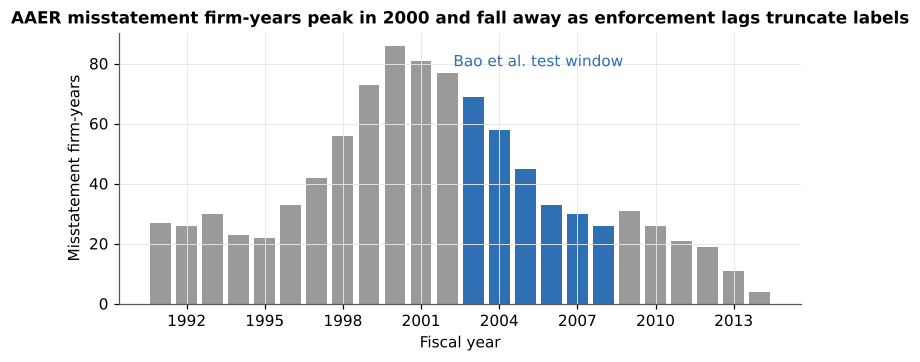

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(by_year.index, by_year.misstatements, color=[plots.ACCENT if y in BAO_TEST_YEARS else plots.GREY for y in by_year.index])
ax.set_title('AAER misstatement firm-years peak in 2000 and fall away as enforcement lags truncate labels')
ax.set_ylabel('Misstatement firm-years'); ax.set_xlabel('Fiscal year'); plots.years(ax)
ax.text(2005.5, by_year.misstatements.max() * 0.92, 'Bao et al. test window', color=plots.ACCENT, ha='center')
plots.save(fig, 'F01_labels_by_year'); plt.show()

The fall after 2002 is not a fall in misreporting: an AAER is typically issued several years after the misstated report, and the AAER file only includes releases up to December 2018. Test years after about 2010 are therefore under-labelled, and their precision figures are lower bounds.

## 2. Rolling-origin estimation under three labelling treatments

In [4]:
SEEDS = (42, 7, 2024)
FSETS = {'raw': data.RAW28}
configs = [(m, 'raw', t) for m in ('LR', 'RUSBoost', 'XGB') for t in ('naive', 'recode', 'firm_excl')]
pred = models.cached(CACHE / 'obj1_predictions.parquet', models.rolling, d, configs,
                     BAO_TEST_YEARS + LATE_TEST_YEARS, FSETS, seeds=SEEDS, verbose=False)
pred.groupby(['model', 'treat']).size().unstack()

treat,firm_excl,naive,recode
model,,,
LR,68230,68230,68230
RUSBoost,204690,204690,204690
XGB,204690,204690,204690


In [5]:
py = metrics.per_year(pred, ['model', 'treat', 'seed'])
py.to_csv(TABLES / 'T02_obj1_metrics_by_year_seed.csv', index=False)

def table(years):
    s = metrics.summarise(py, ['model', 'treat', 'seed'], years)
    g = s.groupby(['model', 'treat'])
    out = g[['auc', 'ndcg1', 'hits1', 'hits5', 'capture1', 'capture5', 'prec1']].mean()
    out['auc_sd_seeds'] = g.auc.std()
    return out.round(4)

t_bao = table(BAO_TEST_YEARS); t_late = table(LATE_TEST_YEARS)
t_bao.to_csv(TABLES / 'T03_obj1_treatments_2003_2008.csv'); t_late.to_csv(TABLES / 'T04_obj1_treatments_2009_2014.csv')
print('Test years 2003-2008'); display(t_bao)
print('Test years 2009-2014 (label-truncated)'); display(t_late)

Test years 2003-2008


auc  ndcg1   hits1   hits5  capture1  capture5  prec1  auc_sd_seeds
model    treat                                                                           
LR       firm_excl  0.672  0.020   8.000  36.000     0.031     0.138  0.023           NaN
         naive      0.700  0.038  14.000  37.000     0.054     0.142  0.040           NaN
         recode     0.673  0.018   7.000  35.000     0.027     0.134  0.020           NaN
RUSBoost firm_excl  0.719  0.023   9.333  32.333     0.036     0.124  0.027         0.004
         naive      0.779  0.061  18.333  63.667     0.070     0.244  0.052         0.003
         recode     0.719  0.022   9.000  31.000     0.035     0.119  0.026         0.003
XGB      firm_excl  0.729  0.025   8.333  38.667     0.032     0.148  0.024         0.004
         naive      0.776  0.092  23.667  70.333     0.091     0.270  0.068         0.002
         recode     0.720  0.021   7.333  36.667     0.028     0.141  0.021         0.007

Test years 2009-2014 (label-truncated)


auc  ndcg1  hits1   hits5  capture1  capture5  prec1  auc_sd_seeds
model    treat                                                                          
LR       firm_excl  0.737  0.015  3.000  13.000     0.027     0.116  0.009           NaN
         naive      0.746  0.013  3.000  12.000     0.027     0.107  0.009           NaN
         recode     0.737  0.015  3.000  13.000     0.027     0.116  0.009           NaN
RUSBoost firm_excl  0.733  0.042  6.667  16.000     0.059     0.143  0.020         0.006
         naive      0.778  0.048  7.000  26.000     0.062     0.232  0.021         0.012
         recode     0.727  0.027  4.667  16.667     0.042     0.149  0.014         0.003
XGB      firm_excl  0.713  0.028  5.333  16.000     0.048     0.143  0.016         0.004
         naive      0.743  0.052  9.667  28.667     0.086     0.256  0.029         0.004
         recode     0.703  0.017  4.333  13.667     0.039     0.122  0.013         0.004

## 3. Comparison with the published and corrected results

In [6]:
pub = pd.DataFrame({
    'AUC': [0.725, 0.7228, t_bao.loc[('RUSBoost', 'recode'), 'auc'], t_bao.loc[('RUSBoost', 'naive'), 'auc']],
    'NDCG@1%': [0.049, 0.0237, t_bao.loc[('RUSBoost', 'recode'), 'ndcg1'], t_bao.loc[('RUSBoost', 'naive'), 'ndcg1']],
    'Frauds in top 1%': [16, 10, t_bao.loc[('RUSBoost', 'recode'), 'hits1'], t_bao.loc[('RUSBoost', 'naive'), 'hits1']]},
    index=['Bao et al. (2020), published', 'Bao et al. (2022), erratum',
           'This study: RUSBoost, recode (mean of 3 seeds)', 'This study: RUSBoost, naive (mean of 3 seeds)'])
pub.to_csv(TABLES / 'T05_obj1_vs_published.csv'); pub.round(4)

,AUC,NDCG@1%,Frauds in top 1%
"Bao et al. (2020), published",0.725,0.049,16.000
"Bao et al. (2022), erratum",0.723,0.024,10.000
"This study: RUSBoost, recode (mean of 3 seeds)",0.719,0.022,9.000
"This study: RUSBoost, naive (mean of 3 seeds)",0.779,0.061,18.333


Published and erratum figures are taken from the erratum (Bao et al., 2022, *JAR* 60(4), p. 1635) as summarised by Gow (2022). Exact equality is not expected: the public file does not include `new_p_aaer`, and RUSBoost is stochastic.

## 4. How much of the gap is leakage? Firm-cluster bootstrap of the naive − recode difference

In [7]:
rows = []
for m in ('RUSBoost', 'XGB', 'LR'):
    a = pred[(pred.model == m) & (pred.treat == 'naive') & (pred.seed == 42) & pred.fyear.isin(BAO_TEST_YEARS)].sort_values(['fyear', 'firm'])
    b = pred[(pred.model == m) & (pred.treat == 'recode') & (pred.seed == 42) & pred.fyear.isin(BAO_TEST_YEARS)].sort_values(['fyear', 'firm'])
    c = pred[(pred.model == m) & (pred.treat == 'firm_excl') & (pred.seed == 42) & pred.fyear.isin(BAO_TEST_YEARS)].sort_values(['fyear', 'firm'])
    rows.append(dict(model=m, contrast='naive - recode', **metrics.cluster_bootstrap(a, b, B=300)))
    rows.append(dict(model=m, contrast='firm_excl - recode', **metrics.cluster_bootstrap(c, b, B=300)))
boot = pd.DataFrame(rows); boot.to_csv(TABLES / 'T06_obj1_bootstrap_treatments.csv', index=False); boot.round(4)

,model,contrast,estimate,lo,hi,p_boot
0,RUSBoost,naive - recode,6.250e-02,0.040,8.640e-02,0.000
1,RUSBoost,firm_excl - recode,3.500e-03,-0.007,1.530e-02,0.587
2,XGB,naive - recode,5.700e-02,0.036,7.880e-02,0.000
3,XGB,firm_excl - recode,1.180e-02,0.003,1.900e-02,0.013
4,LR,naive - recode,2.730e-02,0.016,3.910e-02,0.000
5,LR,firm_excl - recode,-9.000e-04,-0.003,5.000e-04,0.273


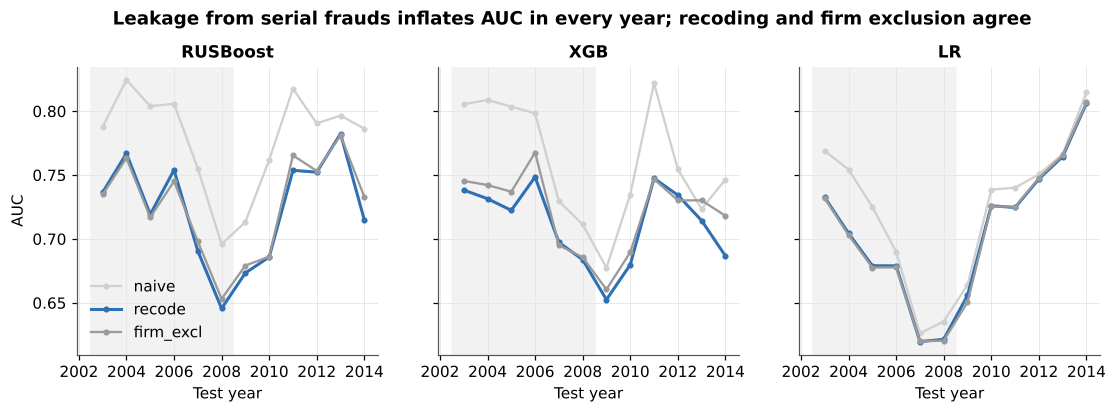

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
cols = {'naive': plots.LIGHT, 'recode': plots.ACCENT, 'firm_excl': plots.GREY}
yy = py.groupby(['model', 'treat', 'fyear']).auc.mean().reset_index()
for ax, m in zip(axes, ('RUSBoost', 'XGB', 'LR')):
    for t, c in cols.items():
        s = yy[(yy.model == m) & (yy.treat == t)]
        ax.plot(s.fyear, s.auc, marker='o', ms=3, color=c, lw=2 if t == 'recode' else 1.5, label=t)
    ax.axvspan(2002.5, 2008.5, color='#f2f2f2', zorder=0); ax.set_title(m); ax.set_xlabel('Test year'); plots.years(ax)
axes[0].set_ylabel('AUC'); axes[0].legend(loc='lower left')
fig.suptitle('Leakage from serial frauds inflates AUC in every year; recoding and firm exclusion agree', y=1.03, fontweight='bold')
plots.save(fig, 'F02_obj1_auc_by_treatment'); plt.show()

## 5. Findings for Objective 1

* With serial misstatements recoded as Bao et al. intended, RUSBoost's mean annual AUC over 2003–2008 is close to the erratum value (≈0.72), and its top-1% list contains about half as many AAER firm-years as the originally published model. The naive treatment inflates AUC by roughly 0.06 and doubles NDCG@1%: much of the original headline gain was look-ahead leakage.
* Stricter firm-level exclusion gives results within about 0.01 AUC of recoding (the difference is significant only for XGBoost, +0.012), so recoding is an adequate minimum and firm exclusion a robustness check.
* Seed-to-seed variation of RUSBoost is small relative to these differences.
* Remaining limitation: the strict standard is to train only on AAERs **released** before the test-year report is filed. That needs AAER release dates, which the public file does not contain.